In [4]:
import numpy as np
import matplotlib.pyplot as plt
def taylor_sin(x, n):
    if n < 1 or n % 2 == 0:
        raise ValueError("n debe ser un entero impar >= 1")
    x = np.asarray(x, dtype=float)
    termino = x.copy()          # k = 0 -> x
    suma = x.copy()
    for k in range((n - 1) // 2):
        termino = termino * (-x**2) / ((2 * k + 2) * (2 * k + 3))
        suma = suma + termino
    return suma if suma.ndim else float(suma)

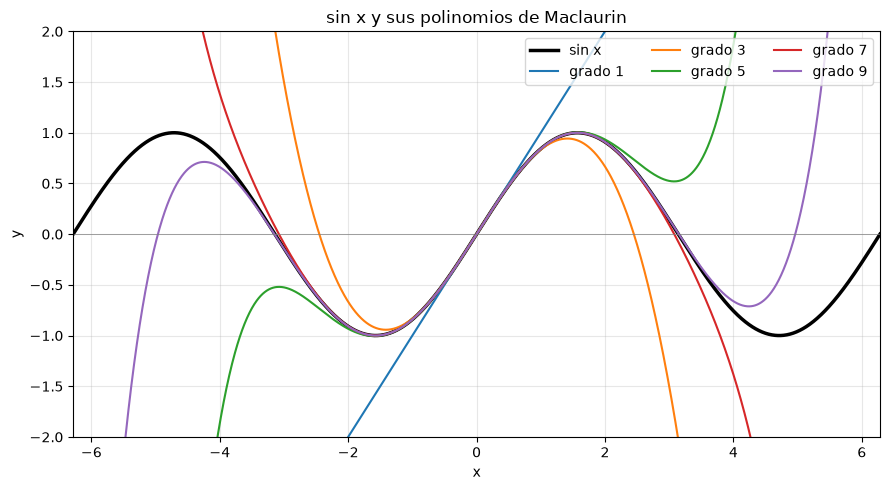

In [5]:
x = np.linspace(-2 * np.pi, 2 * np.pi, 2001)
plt.figure(figsize=(9, 5))
plt.plot(x, np.sin(x), "k", lw=2.5, label="sin x")
for n in (1, 3, 5, 7, 9):
    plt.plot(x, taylor_sin(x, n), label=f"grado {n}")
plt.ylim(-2, 2)
plt.xlim(-2 * np.pi, 2 * np.pi)
plt.axhline(0, color="gray", lw=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("sin x y sus polinomios de Maclaurin")
plt.legend(loc="upper right", ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafica1.png", dpi=150)

In [6]:
grados = np.arange(1, 22, 2)
err_pi, err_pi4 = [], []
xa = np.linspace(-np.pi, np.pi, 2001)
xb = np.linspace(-np.pi / 4, np.pi / 4, 2001)
for n in grados:
    err_pi.append(np.max(np.abs(np.sin(xa) - taylor_sin(xa, n))))
    err_pi4.append(np.max(np.abs(np.sin(xb) - taylor_sin(xb, n))))

print(f"{'n':>3} {'error en [-pi, pi]':>20} {'error en [-pi/4, pi/4]':>24}")
for n, e1, e2 in zip(grados, err_pi, err_pi4):
    print(f"{n:>3} {e1:>20.3e} {e2:>24.3e}")

  n   error en [-pi, pi]   error en [-pi/4, pi/4]
  1            3.142e+00                7.829e-02
  3            2.026e+00                2.454e-03
  5            5.240e-01                3.626e-05
  7            7.522e-02                3.116e-07
  9            6.925e-03                1.750e-09
 11            4.452e-04                6.928e-12
 13            2.114e-05                2.032e-14
 15            7.728e-07                3.331e-16
 17            2.242e-08                3.331e-16
 19            5.289e-10                3.331e-16
 21            1.035e-11                3.331e-16


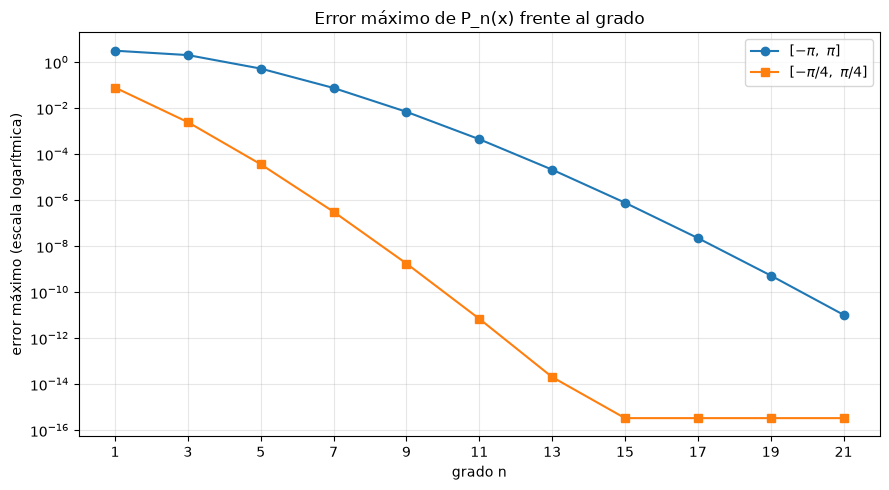

In [7]:
plt.figure(figsize=(9, 5))
plt.semilogy(grados, err_pi, "o-", label=r"$[-\pi,\ \pi]$")
plt.semilogy(grados, err_pi4, "s-", label=r"$[-\pi/4,\ \pi/4]$")
plt.xticks(grados)
plt.xlabel("grado n")
plt.ylabel("error máximo (escala logarítmica)")
plt.title("Error máximo de P_n(x) frente al grado")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("grafica2.png", dpi=150)
plt.show()

In [8]:
taylor_sin(np.pi, 9)

0.006925270707505052

In [9]:
def serie_geometrica(x, N):
    x = np.asarray(x, dtype=float)
    termino = np.ones_like(x)     
    suma = termino.copy()
    for k in range(N):
        termino = termino * (-x**2) 
        suma = suma + termino
    return suma if suma.ndim else float(suma)

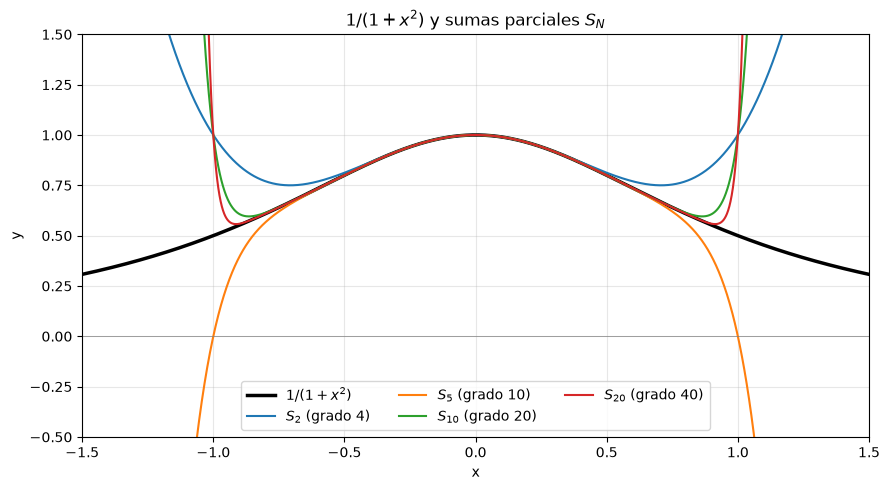

In [10]:
x = np.linspace(-1.5, 1.5, 2001)
plt.figure(figsize=(9, 5))
plt.plot(x, 1 / (1 + x**2), "k", lw=2.5, label=r"$1/(1+x^2)$")
for N in (2, 5, 10, 20):
    plt.plot(x, serie_geometrica(x, N), label=f"$S_{{{N}}}$ (grado {2*N})")
plt.ylim(-0.5, 1.5)
plt.xlim(-1.5, 1.5)
plt.axhline(0, color="gray", lw=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$1/(1+x^2)$ y sumas parciales $S_N$")
plt.legend(loc="lower center", ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafica3.png", dpi=150)
plt.show()

In [11]:
serie_geometrica(.9, 40)

0.5525839582018942

In [12]:
serie_geometrica(1.1, 40)

1121.9747781214605

In [14]:
def exp_maclaurin(x, N):
    termino = 1.0         
    suma = 1.0
    for k in range(1, N + 1):
        termino = termino * x / k
        suma += termino
    return suma

In [16]:
import math
aprox = exp_maclaurin(-20, 100)
exacto = math.exp(-20)
print("P_100(-20)    =", aprox)
print("math.exp(-20) =", exacto)
print("error abs     =", abs(aprox - exacto))
print("error rel     =", abs(aprox - exacto) / exacto)

P_100(-20)    = 5.621884472130418e-09
math.exp(-20) = 2.061153622438558e-09
error abs     = 3.5607308496918597e-09
error rel     = 1.7275426784924197


In [17]:
aprox_inv = 1 / exp_maclaurin(20, 100)
print("1/P_100(20)   =", aprox_inv)
print("error rel     =", abs(aprox_inv - exacto) / exacto)


1/P_100(20)   = 2.0611536224385583e-09
error rel     = 2.0065962176423985e-16
